# Local-data portfolio simulation

This demo uses only the repository's generated Parquet files. It trains the existing random-forest classifier on the local train split, predicts the local test split, and compares an all-in/all-out portfolio with fee-adjusted buy-and-hold.

In [4]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import config
from src.modeling.train import FEATURE_COLUMNS, make_models
from src.simulation import PortfolioSimulator

In [5]:
clean = pd.read_parquet(config.INTERIM_DIR / "btcusdt_1D_clean.parquet")
train = pd.read_parquet(config.PROCESSED_DIR / "btcusdt_1D_train.parquet")
test = pd.read_parquet(config.PROCESSED_DIR / "btcusdt_1D_test.parquet")

model = make_models(random_state=0)["random_forest"]
model.fit(train[FEATURE_COLUMNS], train["label"])
test_pred = model.predict(test[FEATURE_COLUMNS])

# Flat predictions are HOLD; directional predictions are BUY or SELL.
signals = pd.Series(test_pred, index=test.index).map({1: 1, -1: -1, 0: "HOLD"})
simulation_data = clean[["close"]].join(signals.rename("signal"), how="inner").dropna()
simulator = PortfolioSimulator(initial_cash=1_000.0, fee=config.TRADING_FEE)
ledger = simulator.run(simulation_data, "signal")
metrics = simulator.performance_metrics(simulation_data["close"])
pd.Series(metrics).to_frame("value")

,value
strategy_total_return_pct,-15.308525
benchmark_total_return_pct,-24.861100
strategy_max_drawdown_pct,-43.048100
benchmark_max_drawdown_pct,-52.971766
strategy_minus_benchmark_pct,9.552575


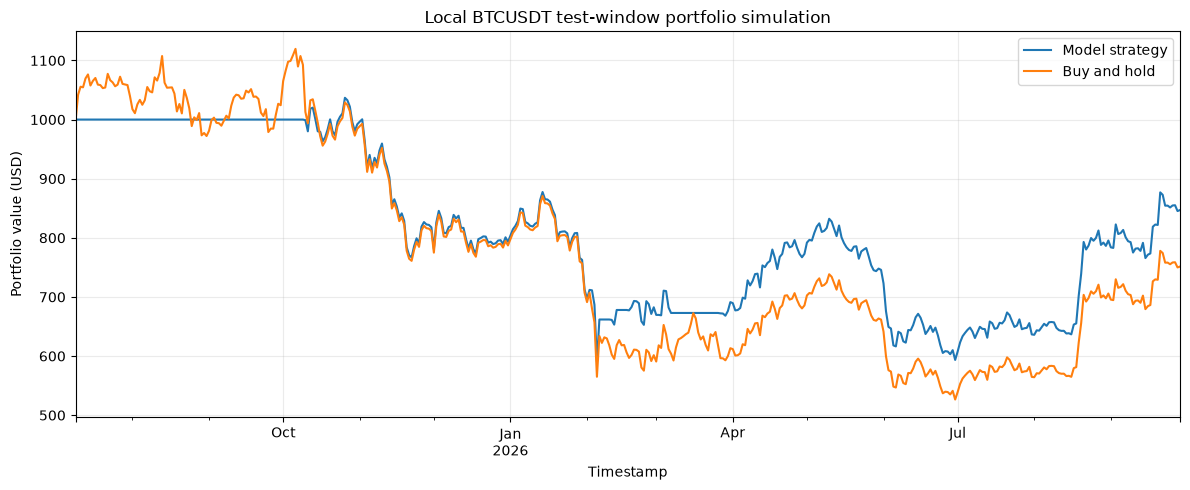

In [6]:
benchmark = simulator.benchmark(simulation_data["close"])
ax = ledger["total_portfolio_value"].plot(figsize=(12, 5), label="Model strategy")
benchmark["total_portfolio_value"].plot(ax=ax, label="Buy and hold")
ax.set_title("Local BTCUSDT test-window portfolio simulation")
ax.set_xlabel("Timestamp")
ax.set_ylabel("Portfolio value (USD)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()